In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

import statsmodels.api as sm


In [2]:
#En primer lugar, importamos los conjuntos x_train , x_test , y_test y_train conseguidos durante el preprocesamiento.ipynb
# x cuenta con las variables predictoras y e y con la variable a predecir (impago) 
#hemos usado estos conjuntos ya que están ya preparados para entrenar y evaluar el  modelo, ya que de lo contrario tendríamos que repetir todo el procespo previo


base_path = Path.cwd()

X_train = pd.read_csv(base_path / "X_train_impago.csv")
X_test = pd.read_csv(base_path / "X_test_impago.csv")

y_train = pd.read_csv(base_path / "y_train_impago.csv").squeeze("columns")
y_test = pd.read_csv(base_path / "y_test_impago.csv").squeeze("columns")

In [ ]:
#se ha eliminado la  la variable prima en el preprocesamiento ya que al calcular el impago de un nuevo cliente, se desconoce la prima del mismo, por lo que
 

In [4]:
#comprobamos la distribucion de impago, para saber cómo se distribuye el dataset(tanto en train como en test) con el objetivo de conocer si ambas clases tienen una presencia similar
#  Cómo se puede observar, el dataset está bastante desbalanceado, teniendo un 84,4% de no impago y un 11,5 % de impago
#una vez sabido esto,lo cual nos ayudará a la hora de interpretar las métricas del modelo, podemos comenzar a entrenar el modelo

 
print("\nPorcentaje de observaciones por clase en train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nPorcentaje de observaciones por clase en test:")
print(y_test.value_counts(normalize=True) * 100)



Porcentaje de observaciones por clase en train:
Impago
0    88.447976
1    11.552024
Name: proportion, dtype: float64

Porcentaje de observaciones por clase en test:
Impago
0    88.449789
1    11.550211
Name: proportion, dtype: float64


In [5]:
#también analizaremos la correlación entre la variable objetivo y las variables predictoras 
#saber la relación lineal que tiene cada variable con el impago nos servirá como primer análisis antes de hacer la regresión

# Analizamos la correlación entre la variable objetivo Impago y las variables predictoras.
# Realizamos este análisis para conocer la relación lineal que presenta cada variable
# con el impago y observar cuáles muestran una mayor asociación positiva o negativa.
# Esto nos sirve como un primer análisis de la relación entre las variables antes de
# entrenar la regresión logística.

datos_correlacion = X_train.copy()
datos_correlacion["Impago"] = y_train.values

correlaciones = (
    datos_correlacion
    .corr()["Impago"]
    .drop("Impago")
    .sort_values(ascending=False)
)

print(correlaciones)

Ratio_Interes                   0.126984
Estado_Civil_Soltero            0.105324
Estudios_Grado Universitario    0.022679
Posesion_Hipoteca_1.0           0.009151
Estudios_Máster                 0.003939
Num_Creditos                    0.000268
Duracion                       -0.006971
Ratio_Deuda_Ingresos           -0.024650
Estudios_Escolar               -0.028209
Scoring_Crediticio             -0.041950
Monto_Inicial                  -0.050373
Estado_Civil_Divorciado        -0.055359
Ingresos                       -0.084079
Meses_Empleo                   -0.162833
Edad                           -0.167416
Name: Impago, dtype: float64


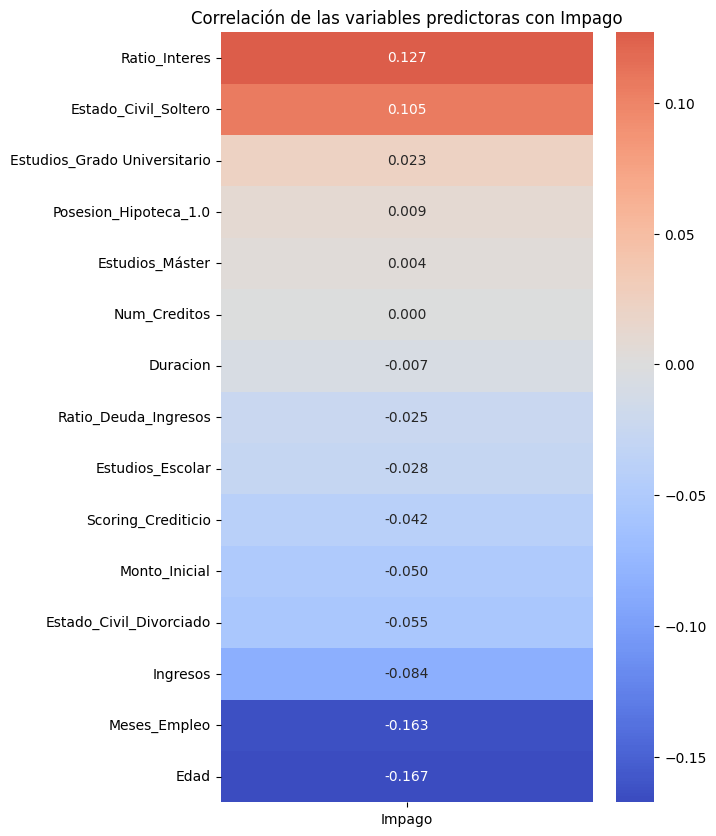

In [6]:
#vistos los resultados podemos obtener ciertas conclusiones así como que existe cierta correlación positiva con ciertas variables , así como el ratio de interés o el estado civil de la persona, por lo que a medida de que esa variable aumente , tiende a aumentar el impago.
#por otro lado, también existe cierta correlación negativa con variables como la edad o los meses de empleo, por lo que a medida que aumenta esa variable el impago tiende a disminuir
#visualizamos los resultados con un gráfico
# Representamos gráficamente las correlaciones para facilitar su interpretación.
import seaborn as sns
import matplotlib.pyplot as plt

correlaciones = correlaciones.sort_values(ascending=False).to_frame(name="Impago")

# Mapa de calor
plt.figure(figsize=(6, 10))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("Correlación de las variables predictoras con Impago")
plt.show()

In [7]:
#una vez los datos están listos, usaremos sklearn para crear y entrenar el modelo
#para estimare la probabilidad de impago, usaremos la regresión logística, ya que la variable impago es binaria(0=no impago 1= impoago)
#y este modelo permite estimar la probabilidad de pertenecer a una o a otra clase
#usaremos fit para que a partir de x_train y de y_train el modelo aprenda la relación entre las variables que se usan para predecir y entre la probabilidad de impago
modelo_log_sklearn = LogisticRegression()

modelo_log_sklearn.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [8]:
#una vez entrenado el modelo, vamos a ver información del modelo, así como el intercepto y los coeficientes obtenidos
#gracias a esto podemos conocer qué variables aumentan o disminuyen la probabilidad de impago y conocer su relación con la variable objetivo
#también obtenemos el accuracy obtenida por el modelo sobre los datos del entrenamiento, lo cual nos sirve para conocer qué  proporción de train han sido clasificadaas adecuadamente 
#aun así , como hemos visto antes, existe un gran desbalance entre el impago y el no impago,por lo que el acuraccy no será sufuiciente para saber si el modelo es adecuado y usaremos metricas como el recall , precision o f1-score



print("\nIntercepto:")
print(modelo_log_sklearn.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X_train.columns,
    "Coeficiente": modelo_log_sklearn.coef_.flatten()
})

print("\nCoeficientes:")
print(coeficientes)


print(
    "\nAccuracy de entrenamiento:",
    modelo_log_sklearn.score(X_train, y_train))


Intercepto:
[-2.33897602]

Coeficientes:
                        Variable  Coeficiente
0                           Edad    -0.346339
1                  Monto_Inicial    -0.019587
2           Ratio_Deuda_Ingresos    -0.051753
3                       Ingresos     0.033537
4             Scoring_Crediticio    -0.122232
5                   Meses_Empleo    -0.264413
6                       Duracion    -0.021865
7                  Ratio_Interes     0.412269
8                   Num_Creditos    -0.000292
9               Estudios_Escolar     0.151713
10  Estudios_Grado Universitario     0.080033
11               Estudios_Máster     0.013010
12       Estado_Civil_Divorciado    -0.015983
13          Estado_Civil_Soltero     0.011214
14         Posesion_Hipoteca_1.0     0.050705

Accuracy de entrenamiento: 0.8843985115130243


Realizamos predicciones probabilísticas:

- Con .predict_proba() se obtiene, para cada observación, la probabilidad predicha de pertenecer a cada una de las dos clases.

- Con .predict() se obtiene, para cada observación, la clasificación predicha por el modelo. Esta clasificación se corresponde con la clase con mayor probabilidad.

In [9]:
#una vez entrenado el modelo, lo utilizamos para conocer la probabilidad de que cada observación de test pertenezca a pago o a impago
#para ello usaremos predict_proba,la cual da probabilidad predicha de pertenecer a cada una de las dos clases.
#gracias a esto podemos conocer el nivel de riesgo de impago de cada cliente
probabilidades = modelo_log_sklearn.predict_proba(X_test)

probabilidades = pd.DataFrame(
    probabilidades,
    columns=modelo_log_sklearn.classes_
)

print("\nPrimeras probabilidades:")
print(probabilidades.head())



Primeras probabilidades:
          0         1
0  0.926026  0.073974
1  0.780904  0.219096
2  0.922638  0.077362
3  0.863845  0.136155
4  0.847868  0.152132


In [10]:

# Nos quedamos con la probabilidad de Impago(1), ya que de esa forma obtenemos una probabilidad concreta de impago para cliente, lo cual será interesante para analizar su riesgo o clasificarlo posteriormente

prob_impago = probabilidades[1]

#tambiénm vamos a transformar las probabilidades en una clasificación de 0 a 1, poniendo un thresold de 0,5 es decir, aquellos usuarios con probabilifdad de impago inferior al 50% serán clasificados como no impago
#mientras que aquellos que tengan una probabilidad de impago igual o mayor que el 50% serán clasificados como impago
#gracias a esto luego podremos comparar las predicciones del modelo con los valores reañes de y_test 
clasificacion = np.where(prob_impago < 0.5, 0, 1)

print("Primeras clasificaciones:")
print(clasificacion[:10])

Primeras clasificaciones:
[0 0 0 0 0 0 0 0 0 0]


In [11]:
#también ajustamos la regresión logística usando statsmodels, ya que nos permite obtener información estadística más detallada sdobre el modelo(r2,std err...)
#ademas, podremnos conocer qué variables contribuyen a explicar el impago
# Statsmodels necesita que todas las variables sean numéricas
X_train_stats = X_train.astype(float)

# Añadir constante para calcular el intercepto
X_train_stats = sm.add_constant(X_train_stats, prepend=True)

modelo_log_statsm = sm.Logit(
    endog=y_train,
    exog=X_train_stats
)

modelo_log_statsm = modelo_log_statsm.fit()

print("\nResumen del modelo:")
print(modelo_log_statsm.summary())

Optimization terminated successfully.
         Current function value: 0.333541
         Iterations 7

Resumen del modelo:
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                61539
Model:                          Logit   Df Residuals:                    61523
Method:                           MLE   Df Model:                           15
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                 0.06807
Time:                        14:55:29   Log-Likelihood:                -20526.
converged:                       True   LL-Null:                       -22025.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -2.3342      0.071 

In [12]:
#calculamos el intervalos de confianza de los coeficientes(95% del modelo)
#gracias a esto conocemos el rango de valores dentro del cual se espera que esté el coeficiente de verdad de cada predictor

intervalos_ci = modelo_log_statsm.conf_int(alpha=0.05).rename(columns={0: "2.5%", 1: "97.5%"})

intervalos_ci

,2.5%,97.5%
const,-2.472857,-2.195473
Edad,-0.446708,-0.227338
Monto_Inicial,-0.060557,0.019949
Ratio_Deuda_Ingresos,-0.085619,-0.017575
Ingresos,-0.023781,0.082883
Scoring_Crediticio,-0.148177,-0.097466
Meses_Empleo,-0.389864,-0.153129
Duracion,-0.047308,0.003391
Ratio_Interes,0.386631,0.437391
Num_Creditos,-0.025827,0.025014


In [13]:
#creamos una tabla con los principales resultados de cada variable 
#metemos el coeficiente , el p-valor, y el intervalo de confianza del 95%
tabla= pd.DataFrame({
    "Variable": modelo_log_statsm.params.index,
    "Coeficiente": modelo_log_statsm.params.values,
    "p-valor": modelo_log_statsm.pvalues.values,
    "IC 2,5 %": modelo_log_statsm.conf_int()[0].values,
    "IC 97,5 %": modelo_log_statsm.conf_int()[1].values
})

tabla.head(15)

,Variable,Coeficiente,p-valor,"IC 2,5 %","IC 97,5 %"
0,const,-2.334165,1.296927e-238,-2.472857,-2.195473
1,Edad,-0.337023,1.719674e-09,-0.446708,-0.227338
2,Monto_Inicial,-0.020304,3.228492e-01,-0.060557,0.019949
3,Ratio_Deuda_Ingresos,-0.051597,2.954158e-03,-0.085619,-0.017575
4,Ingresos,0.029551,2.774739e-01,-0.023781,0.082883
5,Scoring_Crediticio,-0.122821,2.221995e-21,-0.148177,-0.097466
6,Meses_Empleo,-0.271496,6.939944e-06,-0.389864,-0.153129
7,Duracion,-0.021959,8.954425e-02,-0.047308,0.003391
8,Ratio_Interes,0.412011,3.756068e-222,0.386631,0.437391
9,Num_Creditos,-0.000407,9.749953e-01,-0.025827,0.025014


In [14]:
#también vamos a obtener las probabilidades de impago con el modelo de statsmodels, la cual no aplica regularización por defecto como scikit-learn

# Convertimos las predictoras a float para que no de error( como ya ha ocurrido)

X_test_statsm = X_test.astype(float)

# Añadimos el intercepto, igual que al entrenar.
X_test_statsm = sm.add_constant(X_test_statsm, has_constant="add")

# Ordenamos las columnas igual que en el modelo entrenado.
X_test_statsm = X_test_statsm[modelo_log_statsm.model.exog_names]

# Obtenemos las probabilidades de impago con Statsmodels.
probabilidades_statsm = modelo_log_statsm.predict(X_test_statsm)

probabilidades_statsm.head(4)

0    0.074101
1    0.218721
2    0.077584
3    0.136021
dtype: float64

In [15]:
# Hallamos la clasificación predicha estableciendo un umbral de probabilidad 0.5

clasificacion = np.where(probabilidades_statsm<0.5, 0, 1)
clasificacion[:4]

array([0, 0, 0, 0])

METRICAS DE RENDIMIENTO


In [16]:
# Accuracy / Aciertos: 
""" 
Mide la proporción de predicciones correctas sobre el total de observaciones evaluadas
"""

from sklearn.metrics import accuracy_score

acierto = accuracy_score(y_test, clasificacion)
error = 1 - acierto
print("Acierto:", round(acierto*100, 2), "%")
print("Error:", round(error*100, 2), "%")

Acierto: 88.43 %
Error: 11.57 %


In [17]:
# Precisión, Recall, f1-score
""" 
Precision: Cada vez que el modelo predijo una clase, acerto ese porcentaje
Recall: De todos los datos que eran de esa clase, detectó ese porcentaje
F1-score: El valor será alto si precisión y sensibilidad son similares, útil para comparar clasificadores.
"""



from sklearn.metrics import classification_report

print(classification_report(y_test, clasificacion))

              precision    recall  f1-score   support

           0       0.88      1.00      0.94     13608
           1       0.20      0.00      0.00      1777

    accuracy                           0.88     15385
   macro avg       0.54      0.50      0.47     15385
weighted avg       0.81      0.88      0.83     15385



[[13604     4]
 [ 1776     1]]


<Axes: >

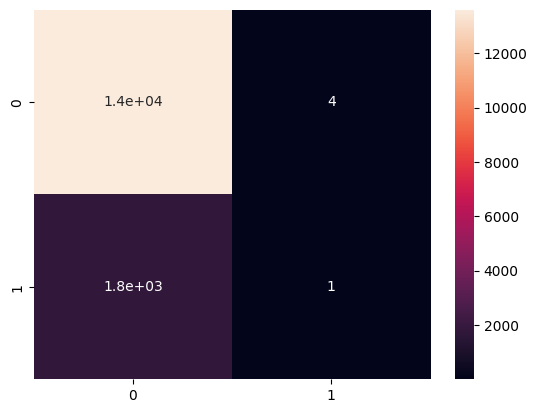

In [18]:
# hacemos la Matriz de confusión

from sklearn.metrics import confusion_matrix

c_matrix = confusion_matrix(y_test, clasificacion)
print(c_matrix)

sns.heatmap(c_matrix, annot=True)

In [19]:
from sklearn.metrics import precision_recall_curve

#sacamos la curva de precision/recall.

prec, rec, thresholds = precision_recall_curve(
    y_test, probabilidades_statsm
)

pd.DataFrame({
    "prec": prec[:-1],
    "rec": rec[:-1],
    "threshold": thresholds
}).iloc[80:100]

,prec,rec,threshold
80,0.115975,0.998875,0.017971
81,0.115983,0.998875,0.017973
82,0.115990,0.998875,0.017980
83,0.115998,0.998875,0.018001
84,0.116005,0.998875,0.018015
85,0.116013,0.998875,0.018089
86,0.116021,0.998875,0.018107
87,0.116028,0.998875,0.018111
88,0.116036,0.998875,0.018147
89,0.116043,0.998875,0.018197


Text(0.5, 1.0, 'PR Curve')

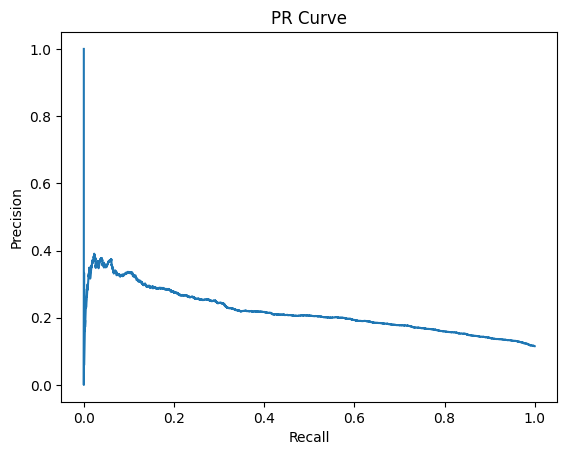

In [20]:
# Creamos la curva

plt.plot(rec, prec)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("PR Curve")

In [21]:
# Curva ROC: 

 
#- tpr (True Positive Rate / Sensibilidad / Recall): Porcentaje de casos positivos (1) reales que el modelo logra detectar
#- fpr (False Positive Rate / 1 - Especificidad): Porcentaje de casos negativos (0) reales que el modelo clasifica erróneamente como positivos.
# threshold: El umbral de probabilidad utilizado para obtener esa combinación específica de tpr y fpr.

from sklearn.metrics import roc_curve

# Seleccionamos únicamente la probabilidad de impago (clase 1).
probabilidades_impago = probabilidades.iloc[:, 1]

# Calculamos los puntos de la curva ROC.
fpr, tpr, threshold = roc_curve(y_test, probabilidades_impago)

pd.DataFrame({
    "tpr": tpr,
    "fpr": fpr,
    "threshold": threshold
})

,tpr,fpr,threshold
0,0.000000,0.000000,inf
1,0.000000,0.000073,0.554141
2,0.000000,0.000147,0.540772
3,0.000563,0.000147,0.538515
4,0.000563,0.001176,0.439091
...,...,...,...
2991,0.998875,0.996914,0.015998
2992,0.999437,0.996914,0.015985
2993,0.999437,0.998530,0.014775
2994,1.000000,0.998530,0.014752


Text(0.5, 1.0, 'Curva ROC')

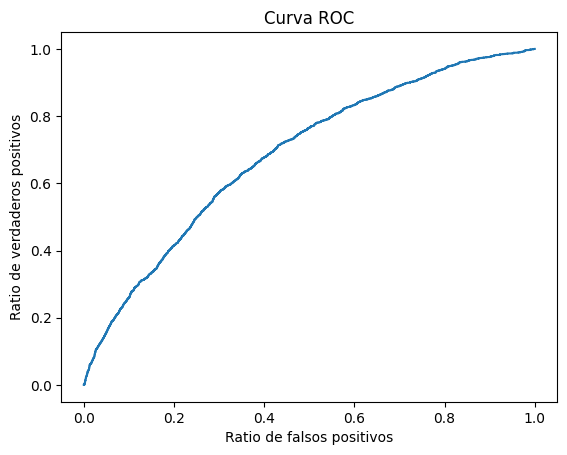

In [22]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr)

plt.xlabel("Ratio de falsos positivos")
plt.ylabel("Ratio de verdaderos positivos")
plt.title("Curva ROC")

OPTIMIZACIÓN DEL MODELO

In [23]:
#Una vez construido y evaluado el modelo inicial, vamos a optimizarlo mediante distintos métodos, así como la regularización, la busqueda de hiperparametros y selección del umbral de clasificación

REGULARIZACIÓN

In [24]:
#vamos a empezar con la regularización. para ello, probaremos los 3 tipos estudiados en clase(l1,l2 y elastic net) para posteriormente elegir el más óptimo, y finalmente elegir el umbral de decisión
#también vamos a probar distintos valores para C ,la cual controla la fuerza de regularización( el inverso de la fuerza de regulareizacion)

from sklearn.model_selection import GridSearchCV, StratifiedKFold



In [25]:
#primero creamos una regresion logistica que servirá como base para gridsearch
#utilizamos solver=saga porque es compatible con las regularizaciones que vamos a probar, y max_iter para  que el modelo tenga suficiente iteraciones

modelo_cs=LogisticRegression(solver="saga",max_iter=5000)

#no añadimos cosas como la validacion cruzada ni las metricas , ya que eso lo implementaremos mediante gridsearch, ya que prueba varias configuracionmes y dice cuál es la más óptima

In [26]:
#ahora definimos distintos valores de c para proibar
#cuanto mayor sea la c, menor regularizacion habrá, mientras que sea menor , hab´ra más regularizaciom
#elegimos (-4,4,50) , es decir, # 50 valores de C entre 0.0001 y 10000, en escala logarítmica
cs=np.logspace(-4,4,50)
cs

array([1.00000000e-04, 1.45634848e-04, 2.12095089e-04, 3.08884360e-04,
       4.49843267e-04, 6.55128557e-04, 9.54095476e-04, 1.38949549e-03,
       2.02358965e-03, 2.94705170e-03, 4.29193426e-03, 6.25055193e-03,
       9.10298178e-03, 1.32571137e-02, 1.93069773e-02, 2.81176870e-02,
       4.09491506e-02, 5.96362332e-02, 8.68511374e-02, 1.26485522e-01,
       1.84206997e-01, 2.68269580e-01, 3.90693994e-01, 5.68986603e-01,
       8.28642773e-01, 1.20679264e+00, 1.75751062e+00, 2.55954792e+00,
       3.72759372e+00, 5.42867544e+00, 7.90604321e+00, 1.15139540e+01,
       1.67683294e+01, 2.44205309e+01, 3.55648031e+01, 5.17947468e+01,
       7.54312006e+01, 1.09854114e+02, 1.59985872e+02, 2.32995181e+02,
       3.39322177e+02, 4.94171336e+02, 7.19685673e+02, 1.04811313e+03,
       1.52641797e+03, 2.22299648e+03, 3.23745754e+03, 4.71486636e+03,
       6.86648845e+03, 1.00000000e+04])

In [27]:
#una vez definidos los valores para c, elegimos las combinaciones( de entre los valores que hemos elegido antes) que va a probar gridsearch
#probaremos con l1,l2 y elastic_net, y para cada una de ellas probaremos distintos valores de c .
#además, para elastic_net, usaremos l1_ratio, que  indica cómo se reparte la regularización entre L1 y L2,si aumentamos su valor, Elastic Net se comporta más como Lasso

param_grid=[{"penalty":["l1"],"C":cs},{"penalty":["l2"],"C":cs},{"penalty":["elasticnet"],"C":cs,"l1_ratio":[.1,.5,.9]}]
param_grid

[{'penalty': ['l1'],
  'C': array([1.00000000e-04, 1.45634848e-04, 2.12095089e-04, 3.08884360e-04,
         4.49843267e-04, 6.55128557e-04, 9.54095476e-04, 1.38949549e-03,
         2.02358965e-03, 2.94705170e-03, 4.29193426e-03, 6.25055193e-03,
         9.10298178e-03, 1.32571137e-02, 1.93069773e-02, 2.81176870e-02,
         4.09491506e-02, 5.96362332e-02, 8.68511374e-02, 1.26485522e-01,
         1.84206997e-01, 2.68269580e-01, 3.90693994e-01, 5.68986603e-01,
         8.28642773e-01, 1.20679264e+00, 1.75751062e+00, 2.55954792e+00,
         3.72759372e+00, 5.42867544e+00, 7.90604321e+00, 1.15139540e+01,
         1.67683294e+01, 2.44205309e+01, 3.55648031e+01, 5.17947468e+01,
         7.54312006e+01, 1.09854114e+02, 1.59985872e+02, 2.32995181e+02,
         3.39322177e+02, 4.94171336e+02, 7.19685673e+02, 1.04811313e+03,
         1.52641797e+03, 2.22299648e+03, 3.23745754e+03, 4.71486636e+03,
         6.86648845e+03, 1.00000000e+04])},
 {'penalty': ['l2'],
  'C': array([1.00000000e-04, 1.4

In [28]:
#una vez definidos los parametros , ya podemos crear gridsearch, la cual probará las distintas configuraciones que hemos establecido y optará por quedarse con una de ellas
#usaremos validacion cruzada con 5 particiones(cv=5), scoring =roc_auc, ya que es la óptima para la regresion logística.
grid=GridSearchCV(estimator=modelo_cs,param_grid=param_grid,cv=5,scoring="roc_auc")
grid

,estimator,LogisticRegre...solver='saga')
,param_grid,"[{'C': array([1.0000...00000000e+04]), 'penalty': ['l1']}, {'C': array([1.0000...00000000e+04]), 'penalty': ['l2']}, ...]"
,scoring,'roc_auc'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [29]:
#una vez creado grid search, lo entrenamos usando los datos de entrenamiento, donde para cada combinación, grid search hará la validación cruzada con 5 particiones
#gracias a esto sabremos cual será la configuracióin con mejor rendimiento
grid.fit(X_train,y_train)


,estimator,LogisticRegre...solver='saga')
,param_grid,"[{'C': array([1.0000...00000000e+04]), 'penalty': ['l1']}, {'C': array([1.0000...00000000e+04]), 'penalty': ['l2']}, ...]"
,scoring,'roc_auc'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l1'


In [30]:
#ahora ya vemos cuál es la configuración más óptima
print(grid.best_estimator_, grid.best_params_,grid.best_score_)


LogisticRegression(C=np.float64(0.013257113655901081), max_iter=5000,
                   penalty='l1', solver='saga') {'C': np.float64(0.013257113655901081), 'penalty': 'l1'} 0.6937994756857699


In [31]:
#es decir, de todas las combinaciones, la de penalty=l1, y c= 0.013257113655901081 es la mejor, teniendo un rocauc medio de 0,69379


#############
 por lo que, las
soluciones de Lasso, son muy inestables si los predictores están altamente
correlacionados.


In [32]:
#aun que sabemos cual es la mejor, comprobamos los m,ejores resultados con una tabla

resultados_grid = pd.DataFrame(grid.cv_results_)

resultados_grid = resultados_grid[
    [
        "param_penalty",
        "param_C",
        "param_l1_ratio",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
)

resultados_grid.head(30)




,param_penalty,param_C,param_l1_ratio,mean_test_score,std_test_score,rank_test_score
13,l1,0.013257,NaN,0.693799,0.005621,1
141,elasticnet,0.013257,0.9,0.693796,0.005647,2
14,l1,0.019307,NaN,0.693779,0.005685,3
144,elasticnet,0.019307,0.9,0.693767,0.005705,4
138,elasticnet,0.009103,0.9,0.693759,0.005605,5
12,l1,0.009103,NaN,0.693752,0.005589,6
15,l1,0.028118,NaN,0.693746,0.005743,7
147,elasticnet,0.028118,0.9,0.693729,0.005758,8
137,elasticnet,0.009103,0.5,0.693719,0.005727,9
134,elasticnet,0.006251,0.5,0.693710,0.005682,10


In [ ]:
#finalmente, guardamos el mejor modelo en base al criterio ROC-AUC, el cual tiene una buena capacidad para diferenciar entre clientes con mayor y menor riesgo de impago
mejor_modelo=grid.best_estimator_
mejor_modelo

,penalty,'l1'
,dual,False
,tol,0.0001
,C,np.float64(0....7113655901081)
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'saga'
,max_iter,5000
,multi_class,'deprecated'


In [72]:
#vamos a tratar de optimizar el modelo al máximo
#para ello, en primer lugar, vamos a tratar de afinar un poco más la c. para ello, haremos una busqueda más precisa alrededr del mejor valor para c que hemo encontrado(0,013)

mejor_C = grid.best_params_["C"]
print("mejor c conseguida:",mejor_C)

#ahora vamos a probar con los valores más cercanos a los que habiamos conseguido antes. para ello, multiplicaremos ese valor por 0.5, que dará  el limite inferior de c,y por 1.5, que  dará el limite supeior. también generaremos 30 valores repartdos en esos limites

valores_C_optimos = np.linspace(
    mejor_C * 0.5,
    mejor_C * 1.5,
    30
)
#añadimis también el c anterior, para asegurar que la nueva busqueda incluya la anterior
valores_C_optimos = np.append(valores_C_optimos, mejor_C)


mejor c conseguida: 0.013257113655901081


In [63]:
valores_C_optimos

array([0.00662856, 0.0070857 , 0.00754284, 0.00799998, 0.00845712,
       0.00891427, 0.00937141, 0.00982855, 0.01028569, 0.01074283,
       0.01119998, 0.01165712, 0.01211426, 0.0125714 , 0.01302854,
       0.01348568, 0.01394283, 0.01439997, 0.01485711, 0.01531425,
       0.01577139, 0.01622854, 0.01668568, 0.01714282, 0.01759996,
       0.0180571 , 0.01851424, 0.01897139, 0.01942853, 0.01988567,
       0.01325711])

In [67]:
#ahora, como tenemos nuevos valores para c, vamos a volver a comparar l1,l2 y elastic net, ya que es posible que l1 no sea la mejor como sí lo era antes
#repetimos el proceso de antes pero esta vez con los nuevos valores de c

param_grid_optimo = [
    {
        "penalty": ["l1"],
        "C": valores_C_optimos
    },
    {
        "penalty": ["l2"],
        "C": valores_C_optimos
    },
    {
        "penalty": ["elasticnet"],
        "C": valores_C_optimos,
        "l1_ratio": [0.1, 0.5, 0.9]
    }
]

grid_optimo = GridSearchCV(
    estimator=modelo_cs,
    param_grid=param_grid_optimo,
    cv=5,
    scoring="roc_auc"
)

grid_optimo.fit(X_train, y_train)

,estimator,LogisticRegre...solver='saga')
,param_grid,"[{'C': array([0.0066... 0.01325711]), 'penalty': ['l1']}, {'C': array([0.0066... 0.01325711]), 'penalty': ['l2']}, ...]"
,scoring,'roc_auc'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l1'


In [69]:
#comparamos los resultados nuevos con los anteriores
print("BÚSQUEDA INICIAL")
print("Penalización:", grid.best_params_["penalty"])
print("C:", grid.best_params_["C"])
print("ROC-AUC:", grid.best_score_)

print("busqueda optima")
print("Mejores hiperparámetros:", grid_optimo.best_params_)
print("ROC-AUC:", grid_optimo.best_score_)

BÚSQUEDA INICIAL
Penalización: l1
C: 0.013257113655901081
ROC-AUC: 0.6937994756857699
busqueda optima
Mejores hiperparámetros: {'C': np.float64(0.014399968281409794), 'penalty': 'l1'}
ROC-AUC: 0.6938030695332961


In [70]:
#por lo que tras este cambio, l1 sigue siendo la mejor penalización, pero el c se ha ajustado un poco, a pesar de que la mejora del ROC-AUC sea mínima
modelo_final = grid_optimo.best_estimator_

In [ ]:
#como hemos cambiado la c , vamos a volver a sacar las probabilidades con el nuevo valor

In [71]:
#sacamos probabilidades sobre x_train sin que se usen los mismos datos con los que se entrenó el modelo, lo cual usaremos para calcular metricas 
#también usaremos esto para posteriormente obtener el umbral de decisión adecuaado que más se acerque a nuestro objetivo, con el que finalmente obtendremos la clasificación final(0/1)
#usaremos la validación cruzada ya que nos permite elegir el umbral sin utilizar test.
from sklearn.model_selection import cross_val_predict

probabilidades_cv = cross_val_predict(
    modelo_final,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

In [ ]:
#inicialmente , usaremos un umbral de 0.5, el cual en base a los resultados y a lo que priorizemos(no detectar a alguien que va a impagar o marcar como arriesgado a alguien que finalmente no impaga)
predicciones_cv = (probabilidades_cv >= 0.5).astype(int)

In [ ]:
#sacamos las metricas

print("Accuracy:", accuracy_score(y_train, predicciones_cv))
print("Precision:", precision_score(y_train, predicciones_cv))
print("Recall:", recall_score(y_train, predicciones_cv))
print("F1:", f1_score(y_train, predicciones_cv))
print("ROC-AUC:", roc_auc_score(y_train, probabilidades_cv))
print("Log Loss:", log_loss(y_train, probabilidades_cv))

print("\nMatriz de confusión:")
print(confusion_matrix(y_train, predicciones_cv))

Accuracy: 0.884479760802093
Precision: 0.5
Recall: 0.0004220002813335209
F1: 0.0008432888264230499
ROC-AUC: 0.6937573988635584
Log Loss: 0.3338098508604272

Matriz de confusión:
[[54427     3]
 [ 7106     3]]


In [ ]:
#con el umbral 0.5 el modelo no funciona como se busca, ya que por ejemplo, la matriz de confusión , indica que de 7109 clientes que impagan, tan solo se clasifican 3 como impago, teniendo un recall de casi 0. 

In [80]:
f1 = []

for umbral in umbrales:
    predicciones = (
        probabilidades_cv >= umbral
    ).astype(int)

    f1.append(
        f1_score(y_train, predicciones)
    )

In [81]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Calculamos Precision y Recall para diferentes valores del umbral.
# El objetivo es encontrar un umbral que consiga un mejor equilibrio
# entre detectar los impagos y no generar demasiados falsos positivos.




print("Accuracy:", accuracy_score(y_train, predicciones_optimas))
print("Umbral óptimo:", umbral_optimo)
print("Precision:", precision[indice_mejor])
print("Recall:", recall[indice_mejor])
print("F1 máximo:", f1[indice_mejor])
print("\nMatriz de confusión:")
print(confusion_matrix(y_train, predicciones_optimas))

Accuracy: 0.7230861729959863
Umbral óptimo: 0.14386223899443526
Precision: 0.21327944572748267
Recall: 0.5196230130820088
F1 máximo: 0.3024274427934013

Matriz de confusión:
[[40804 13626]
 [ 3415  3694]]


In [82]:
# Convertimos las probabilidades en 0 y 1 utilizando el nuevo
# umbral encontrado mediante el máximo F1 Score.

predicciones_optimas = (
    probabilidades_cv >= umbral_optimo
).astype(int)

print("Accuracy:", accuracy_score(y_train, predicciones_optimas))
print("Precision:", precision_score(y_train, predicciones_optimas))
print("Recall:", recall_score(y_train, predicciones_optimas))
print("F1:", f1_score(y_train, predicciones_optimas))

print("\nMatriz de confusión:")
print(confusion_matrix(y_train, predicciones_optimas))

Accuracy: 0.7230861729959863
Precision: 0.21327944572748267
Recall: 0.5196230130820088
F1: 0.3024274427934013

Matriz de confusión:
[[40804 13626]
 [ 3415  3694]]


In [ ]:
#por lo que, con el umbral 0,14 los resultados que conseguimos son bastante distintos.
#en este caso, hemos maximizado f1, el cual trata precision y recall con la misma importancia, equilibrando los falsos positivos y los falsos negativos.
#aun así, en nuestro caso, consideramos que el falso negativo es más peligroso económicamente que el falso positivo, ya que si no se detecta que un cliente pueda impagar, se le podría asginar una prima baja o asumir un riesgo bajo. sin embargo, priorizar el falso positivo también puede suponer factores como asignar primas demasiado elevadas a los clientes y que pueda manchar la reputación de la empresa o acabar perdiendo clientes.